# 04 - EDA & Visualisasi: Pemerataan Faskes Indonesia

**Tujuan**
- Menyajikan sebaran indikator kunci antarprovinsi.
- Membandingkan pola antarwilayah (Sumatera, Jawa, Nusa Tenggara, Kalimantan, Sulawesi, Maluku-Papua).
- Menjadi dasar visual untuk analisis kesenjangan dan clustering di notebook 05.

Semua figur disimpan ke `outputs/figures/`.

## 0. Setup

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["font.size"] = 10

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
TABLE_DIR = ROOT / "outputs" / "tables"
for d in (FIG_DIR, TABLE_DIR):
    d.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(PROCESSED / "faskes_features.csv")
print("Data:", df.shape)

Data: (38, 51)


## 1. Pemetaan wilayah

In [2]:
REGION_MAP = {
    "Aceh": "Sumatera", "Sumatera Utara": "Sumatera", "Sumatera Barat": "Sumatera",
    "Riau": "Sumatera", "Jambi": "Sumatera", "Sumatera Selatan": "Sumatera",
    "Bengkulu": "Sumatera", "Lampung": "Sumatera",
    "Kepulauan Bangka Belitung": "Sumatera", "Kepulauan Riau": "Sumatera",
    "DKI Jakarta": "Jawa", "Jawa Barat": "Jawa", "Jawa Tengah": "Jawa",
    "DI Yogyakarta": "Jawa", "Jawa Timur": "Jawa", "Banten": "Jawa",
    "Bali": "Nusa Tenggara", "Nusa Tenggara Barat": "Nusa Tenggara",
    "Nusa Tenggara Timur": "Nusa Tenggara",
    "Kalimantan Barat": "Kalimantan", "Kalimantan Tengah": "Kalimantan",
    "Kalimantan Selatan": "Kalimantan", "Kalimantan Timur": "Kalimantan",
    "Kalimantan Utara": "Kalimantan",
    "Sulawesi Utara": "Sulawesi", "Sulawesi Tengah": "Sulawesi",
    "Sulawesi Selatan": "Sulawesi", "Sulawesi Tenggara": "Sulawesi",
    "Gorontalo": "Sulawesi", "Sulawesi Barat": "Sulawesi",
    "Maluku": "Maluku-Papua", "Maluku Utara": "Maluku-Papua",
    "Papua Barat": "Maluku-Papua", "Papua Barat Daya": "Maluku-Papua",
    "Papua": "Maluku-Papua", "Papua Selatan": "Maluku-Papua",
    "Papua Tengah": "Maluku-Papua", "Papua Pegunungan": "Maluku-Papua",
}
df["region"] = df["Provinsi"].map(REGION_MAP)
assert df["region"].notna().all(), "Ada provinsi yang tidak terpetakan ke region"
print(df["region"].value_counts())

region
Sumatera         10
Maluku-Papua      8
Jawa              6
Sulawesi          6
Kalimantan        5
Nusa Tenggara     3
Name: count, dtype: int64


## 2. Statistik deskriptif nasional

In [3]:
COLS = ["pkm_per100k", "rs_per100k", "faskes_per_1000km2", "desa_pkm_pct", "desa_rs_pct"]
stat = df[COLS].describe().T
stat["median"] = df[COLS].median()
stat["cv"] = df[COLS].std() / df[COLS].mean()
display(stat.round(2))
stat.to_csv(TABLE_DIR / "statistik_deskriptif_eda.csv")

,count,mean,std,min,25%,50%,75%,max,median,cv
pkm_per100k,38.0,6.53,4.07,0.41,3.60,5.50,8.12,18.44,5.50,0.62
rs_per100k,38.0,1.39,0.44,0.53,1.05,1.30,1.75,2.35,1.30,0.31
faskes_per_1000km2,38.0,21.54,58.09,0.83,3.63,7.94,12.91,359.78,7.94,2.70
desa_pkm_pct,38.0,13.59,4.37,5.54,11.30,12.53,15.82,27.40,12.53,0.32
desa_rs_pct,38.0,4.60,7.58,0.34,1.74,2.65,4.32,46.82,2.65,1.65


## 3. Ranking akses puskesmas per kapita

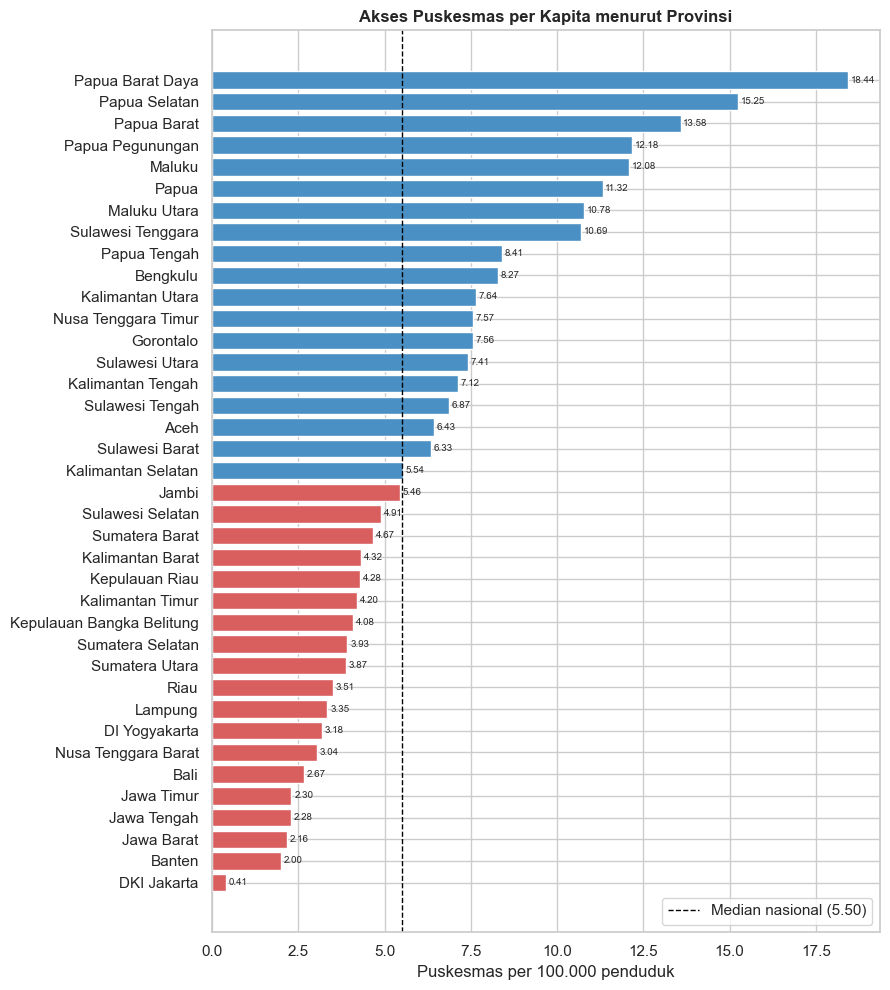

In [4]:
d = df.sort_values("pkm_per100k")
colors = ["#d95f5f" if v < df["pkm_per100k"].median() else "#4a90c4" for v in d["pkm_per100k"]]
fig, ax = plt.subplots(figsize=(9, 10))
bars = ax.barh(d["Provinsi"], d["pkm_per100k"], color=colors, edgecolor="white")
ax.axvline(df["pkm_per100k"].median(), color="black", linestyle="--", lw=1,
           label=f"Median nasional ({df['pkm_per100k'].median():.2f})")
for bar, v in zip(bars, d["pkm_per100k"]):
    ax.text(v + 0.08, bar.get_y() + bar.get_height() / 2, f"{v:.2f}", va="center", fontsize=7)
ax.set_xlabel("Puskesmas per 100.000 penduduk")
ax.set_title("Akses Puskesmas per Kapita menurut Provinsi", weight="bold")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "ranking_pkm_perkapita.png", dpi=150)
plt.show()

**Insight**: Rentang rasio sangat lebar (0,4–18,4 puskesmas per 100.000).
DKI Jakarta memiliki rasio terendah karena layanan bertumpu pada RS/klinik, sedangkan
provinsi berpopulasi kecil di timur memiliki rasio tinggi. Median nasional menjadi
pembanding yang lebih adil daripada rata-rata yang terdistorsi outlier.

## 4. Distribusi tiap indikator

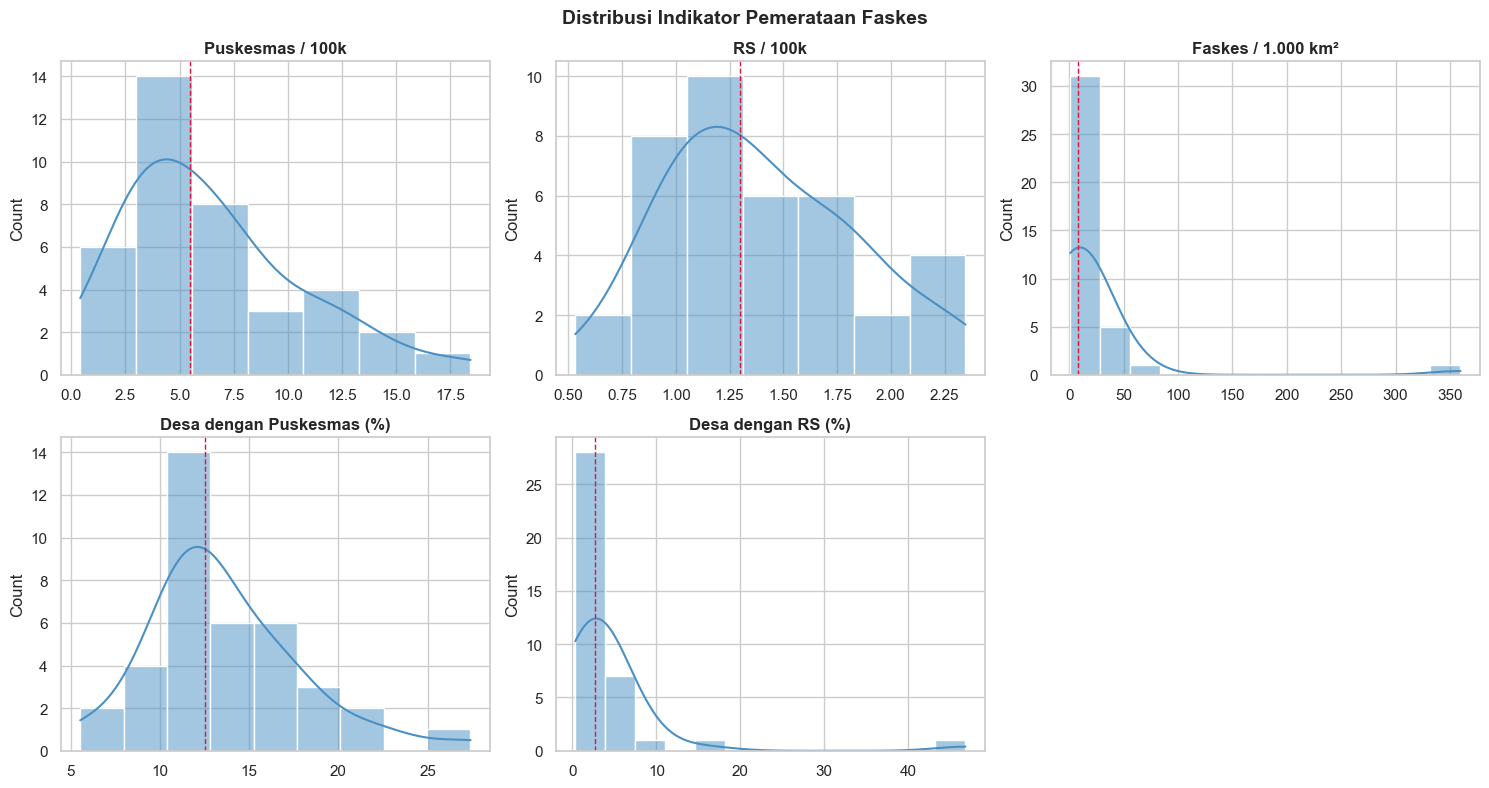

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_cols = ["pkm_per100k", "rs_per100k", "faskes_per_1000km2", "desa_pkm_pct", "desa_rs_pct"]
titles = ["Puskesmas / 100k", "RS / 100k", "Faskes / 1.000 km²", "Desa dengan Puskesmas (%)", "Desa dengan RS (%)"]
for ax, col, title in zip(axes.flat, plot_cols, titles):
    sns.histplot(df[col], kde=True, ax=ax, color="#4a90c4")
    ax.axvline(df[col].median(), color="crimson", ls="--", lw=1)
    ax.set_title(title)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
fig.suptitle("Distribusi Indikator Pemerataan Faskes", weight="bold", fontsize=14)
fig.tight_layout()
fig.savefig(FIG_DIR / "distribusi_indikator.png", dpi=150)
plt.show()

## 5. Perbandingan antarwilayah

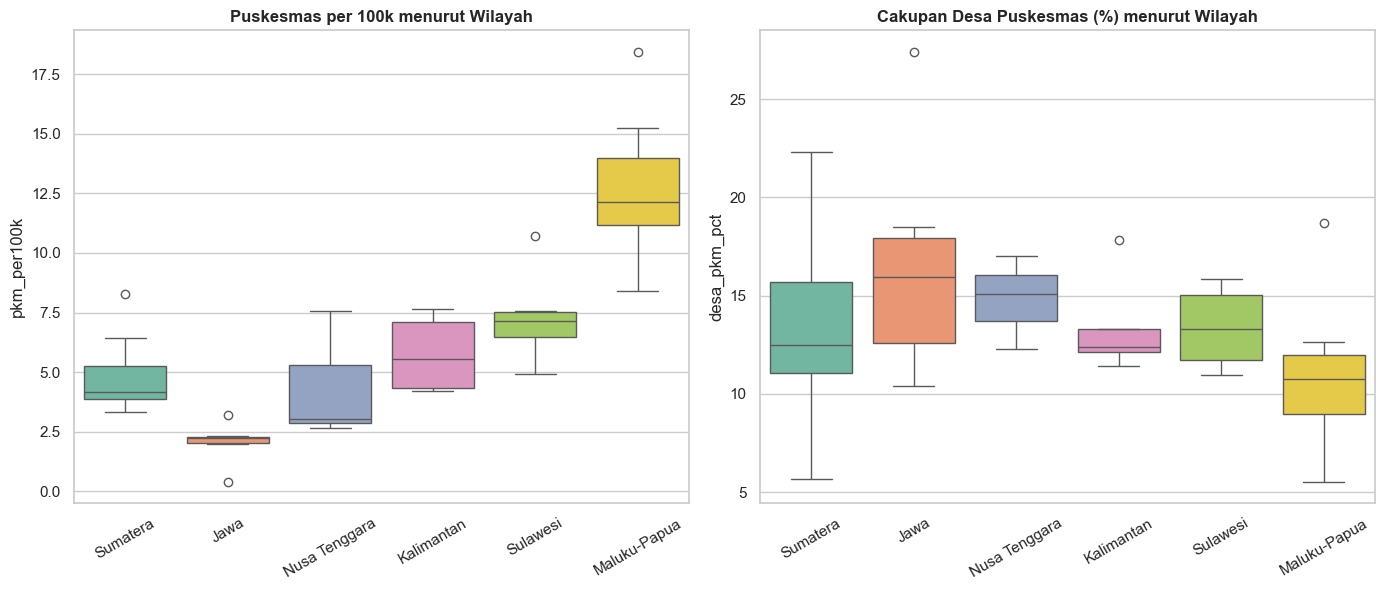

               pkm_per100k  rs_per100k  desa_pkm_pct  desa_rs_pct
region                                                           
Jawa                  2.22        1.06         15.95         6.72
Kalimantan            5.54        1.19         12.40         2.23
Maluku-Papua         12.13        1.55         10.75         1.27
Nusa Tenggara         3.04        1.15         15.08         3.56
Sulawesi              7.14        1.39         13.28         2.50
Sumatera              4.18        1.30         12.47         2.83


In [6]:
order = ["Sumatera", "Jawa", "Nusa Tenggara", "Kalimantan", "Sulawesi", "Maluku-Papua"]
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(data=df, x="region", y="pkm_per100k", order=order, ax=axes[0], palette="Set2")
axes[0].set_title("Puskesmas per 100k menurut Wilayah")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)

sns.boxplot(data=df, x="region", y="desa_pkm_pct", order=order, ax=axes[1], palette="Set2")
axes[1].set_title("Cakupan Desa Puskesmas (%) menurut Wilayah")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIG_DIR / "boxplot_wilayah.png", dpi=150)
plt.show()

print(df.groupby("region")[["pkm_per100k", "rs_per100k", "desa_pkm_pct", "desa_rs_pct"]].median().round(2))

**Insight**: Wilayah timur (Maluku-Papua) punya rasio puskesmas per kapita tinggi
tetapi cakupan desa dan kepadatan faskes rendah. Artinya, ketersediaan per penduduk
tidak otomatis berarti mudah dijangkau secara geografis.

## 6. Akses per kapita vs akses geografis

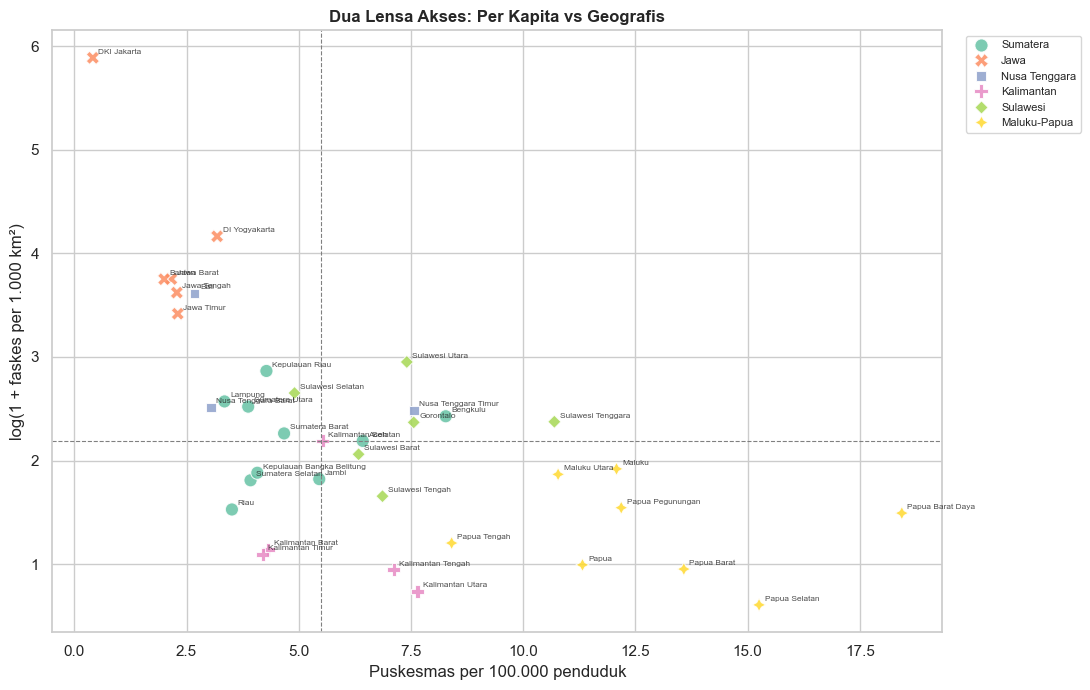

In [7]:
fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=df, x="pkm_per100k", y="log_faskes_per_1000km2",
                hue="region", style="region", s=90, alpha=0.85, ax=ax)
for _, row in df.iterrows():
    ax.annotate(row["Provinsi"], (row["pkm_per100k"], row["log_faskes_per_1000km2"]),
                xytext=(4, 3), textcoords="offset points", fontsize=6, alpha=0.8)
ax.axvline(df["pkm_per100k"].median(), color="gray", ls="--", lw=0.8)
ax.axhline(df["log_faskes_per_1000km2"].median(), color="gray", ls="--", lw=0.8)
ax.set_xlabel("Puskesmas per 100.000 penduduk")
ax.set_ylabel("log(1 + faskes per 1.000 km²)")
ax.set_title("Dua Lensa Akses: Per Kapita vs Geografis", weight="bold")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "scatter_kapita_geografis.png", dpi=150)
plt.show()

**Insight**: Kuadran kiri-atas (rasio per kapita rendah, kepadatan tinggi) diisi provinsi
Jawa yang padat. Kuadran kiri-bawah dan kanan-bawah terkonsentrasi di luar Jawa.
Tidak ada provinsi yang unggul pada kedua lensa sekaligus — ini inti persoalan pemerataan.

## 7. Korelasi antarindikator

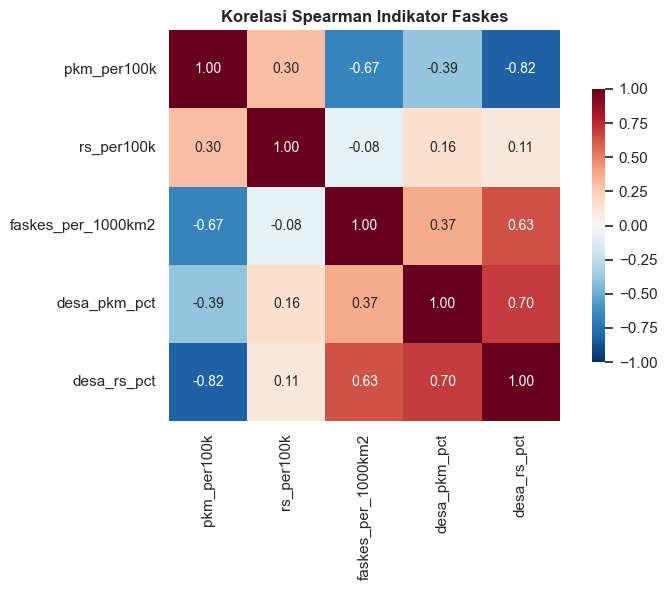

In [8]:
corr = df[COLS].corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            center=0, square=True, cbar_kws={"shrink": .7}, ax=ax)
ax.set_title("Korelasi Spearman Indikator Faskes", weight="bold")
fig.tight_layout()
fig.savefig(FIG_DIR / "heatmap_korelasi.png", dpi=150)
plt.show()

## 8. Cakupan desa vs kepadatan faskes

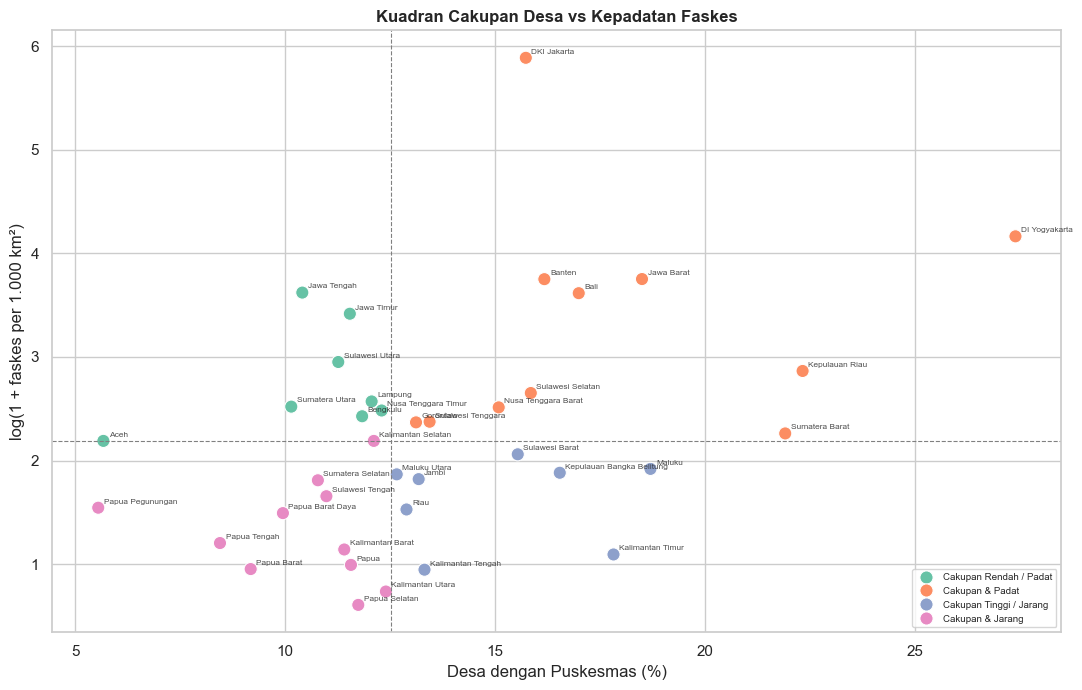

kuadran        Cakupan & Jarang  Cakupan & Padat  Cakupan Rendah / Padat  \
region                                                                     
Jawa                          0                4                       2   
Kalimantan                    3                0                       0   
Maluku-Papua                  6                0                       0   
Nusa Tenggara                 0                2                       1   
Sulawesi                      1                3                       1   
Sumatera                      1                2                       4   

kuadran        Cakupan Tinggi / Jarang  
region                                  
Jawa                                 0  
Kalimantan                           2  
Maluku-Papua                         2  
Nusa Tenggara                        0  
Sulawesi                             1  
Sumatera                             3  


In [9]:
med_cov = df["desa_pkm_pct"].median()
med_den = df["log_faskes_per_1000km2"].median()
df["kuadran"] = np.where(
    df["desa_pkm_pct"] >= med_cov,
    np.where(df["log_faskes_per_1000km2"] >= med_den, "Cakupan & Padat", "Cakupan Tinggi / Jarang"),
    np.where(df["log_faskes_per_1000km2"] >= med_den, "Cakupan Rendah / Padat", "Cakupan & Jarang"),
)

fig, ax = plt.subplots(figsize=(11, 7))
sns.scatterplot(data=df, x="desa_pkm_pct", y="log_faskes_per_1000km2",
                hue="kuadran", palette="Set2", s=90, ax=ax)
ax.axvline(med_cov, color="gray", ls="--", lw=0.8)
ax.axhline(med_den, color="gray", ls="--", lw=0.8)
for _, row in df.iterrows():
    ax.annotate(row["Provinsi"], (row["desa_pkm_pct"], row["log_faskes_per_1000km2"]),
                xytext=(4, 3), textcoords="offset points", fontsize=6, alpha=0.8)
ax.set_xlabel("Desa dengan Puskesmas (%)")
ax.set_ylabel("log(1 + faskes per 1.000 km²)")
ax.set_title("Kuadran Cakupan Desa vs Kepadatan Faskes", weight="bold")
ax.legend(fontsize=7, loc="lower right")
fig.tight_layout()
fig.savefig(FIG_DIR / "kuadran_cakupan_kepadatan.png", dpi=150)
plt.show()

print(pd.crosstab(df["region"], df["kuadran"]))

## 9. Ringkasan EDA

- Distribusi faskes sangat timpang; DKI Jakarta ekstrem pada kepadatan, sedangkan rasio
  per kapita justru rendah.
- Wilayah timur: rasio per kapita tinggi, tetapi cakupan desa dan kepadatan rendah.
- Jawa: kepadatan tinggi, rasio per kapita rendah, cakupan desa bervariasi.
- Dua lensa (per kapita dan geografis) tidak selalu searah → dasar kuat untuk clustering
  multivariat di notebook 05.